In [1]:
import sys
sys.path.append("..")
import numpy as np
from src import funktioner as fn

rng = np.random.default_rng(42)

Medel, median, min och max för: age, weight, height, systolic_bp, cholesterol.


In [2]:
fn.describe(fn.load_data(), fn.columns)

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


Histogram över blodtryck

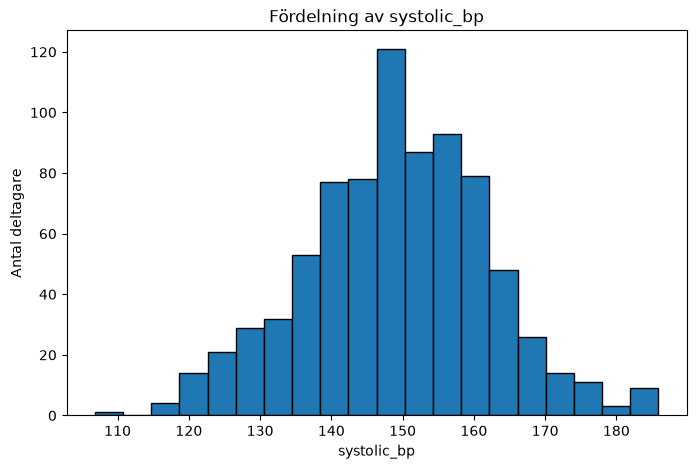

In [3]:
fn.plot_hist(fn.load_data(), "systolic_bp")

Boxplot över vikt per kön

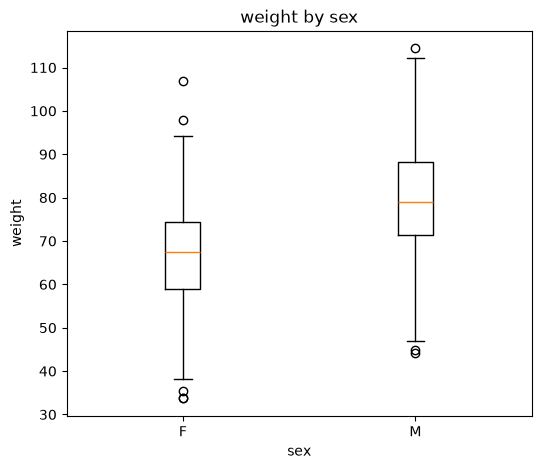

In [4]:
fn.plot_box_by_group(fn.load_data(), "weight", "sex")

Stapeldiagram över andelen rökare

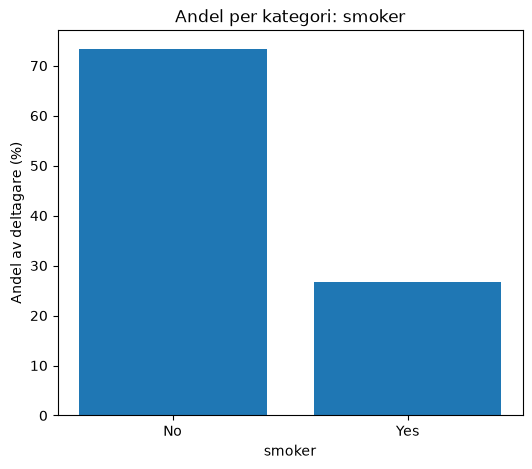

In [5]:
fn.plot_share_bar(fn.load_data(), "smoker")

Jämförelse av den verkliga andelen med den simulerade andelen i datasetet

In [6]:
p_disease = fn.disease_share(fn.load_data())
print(f"Andel av deltagare med sjukdom: {p_disease:.3f}")
simulated = fn.simulate_disease(p_disease, 1000, rng)
print(f"Andel av deltagare med sjukdom i simulering: {simulated.mean():.3f}")

Andel av deltagare med sjukdom: 0.059
Andel av deltagare med sjukdom i simulering: 0.054


Andelen sjuka i simuleringen ligger runt det verkliga antalet, ibland lite högre och ibland lite lägre.

Konfidensintervall för medelvärdet av systolic_bp

In [7]:
bp = fn.load_data()["systolic_bp"]
low, high = fn.ci_mean_normal(bp)
mean_bp = bp.mean()
print(f"Medelvärde: {mean_bp:.2f}, 95% konfidensintervall: ({low:.2f}, {high:.2f})")

Medelvärde: 149.18, 95% konfidensintervall: (148.29, 150.07)


Vi testar hypotesen "Rökare har högre medelblodtryck än icke-rökare".

- **H0:** Rökare och icke-rökare har samma medelblodtryck, alltså ingen skillnad.
- **H1:** Rökare har högre medelblodtryck än icke-rökare.
- **Signifikansnivå:** 5 % (0.05)


In [8]:
smoker_bp = fn.load_data().loc[fn.load_data()["smoker"] == "Yes", "systolic_bp"]
non_smoker_bp = fn.load_data().loc[fn.load_data()["smoker"] == "No", "systolic_bp"]

print(f"Rökare: medel {smoker_bp.mean():.2f} mmHg (n={len(smoker_bp)})")
print(f"Icke-rökare: medel {non_smoker_bp.mean():.2f} mmHg (n={len(non_smoker_bp)})")

Rökare: medel 149.52 mmHg (n=213)
Icke-rökare: medel 149.05 mmHg (n=587)


In [9]:
observed, p_value, boot_diffs = fn.mean_diff_test(smoker_bp, non_smoker_bp, 10_000, rng)

print(f"Observerad skillnad: {observed:.2f} mmHg")
print(f"p-värde: {p_value:.4f}")

Observerad skillnad: 0.47 mmHg
p-värde: 0.3271


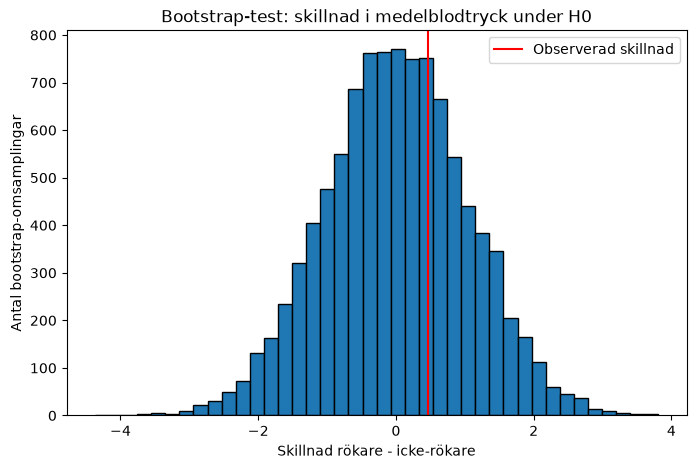

In [10]:
fn.plot_mean_diffs(boot_diffs, observed)

Rökare har ett medelblodtryck på 149.52 mmHg och icke-rökare 149.05 mmHg, en
observerad skillnad på 0.47 mmHg. Bootstrap-testet ger ett p-värde på
0.33.

Grafen visar skillnader som kan uppstå av ren slump om H0 stämmer.
Den röda linjen ligger nära mitten vilket betyder att skillnaden lätt kan hända av ren slump.

På grund av detta så kan vi inte bevisa att varken H1 eller H0 stämmer. Det finns fortfarande en chans att någon av hypoteserna stämmer men datan ger inte en tillräckligt stor skillnad för att det ska vara statistiskt signifikant då p-värdet är större än 0.05